In [1]:
from pathlib import Path
import sys, platform, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import __version__ as sklearn_version
from sklearn.model_selection import train_test_split, GroupShuffleSplit, StratifiedGroupKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, balanced_accuracy_score,
                             cohen_kappa_score, roc_auc_score, roc_curve, auc, log_loss,
                             brier_score_loss)
from sklearn.inspection import permutation_importance
from sklearn.decomposition import PCA
SEED=42
CLASSES=[0,1,2]
LABELS=['Low (0)','Medium (1)','High (2)']
OUT=Path('lung_outputs'); OUT.mkdir(exist_ok=True)
print('Python:',sys.version.split()[0], 'scikit-learn:',sklearn_version)


Python: 3.13.9 scikit-learn: 1.7.2


In [2]:
# Load the unchanged original CSV. If the CSV is not in the current folder,
# use the embedded backup of exactly the same file (works offline / Colab).
from pathlib import Path
from io import BytesIO
import gzip, base64

filenames = ('Lungs(1).csv', 'Lungs.csv', 'Lungs (1).csv')
locations = [Path.cwd(), Path.cwd() / 'data', Path('/mnt/data'), Path('/content')]
candidates = [folder / name for folder in locations for name in filenames]
DATA_PATH = next((p for p in candidates if p.is_file()), None)

# Backup of the supplied Lungs(1).csv, compressed and encoded for portability.
_EMBEDDED_CSV_GZ_B64 = (
    "H4sIAAAAAAAC/52dy24cR5pG9wb8DnyAWjAjb1VLtw3PDGBMJ8aLXtNSWSKaQ2JIqmfcTz/ficwqFimhzTgQdKPqVN7+jPjjO8ri7f3H4//tlp"
    "vn2+P989V/fNz98Om4+7djvvq4++H28Wp5uLv78nz7cL/74e7Dw+eHu6svT8fdT1+enq9+uLs7Pn76Y/fXDx++8AYP9zd3V/9+88+bx49PvMXx"
    "+fbD1X/dPv199+Hz48N9/vLLl/tPVz/dPh1v8h5/ubm7uf9w/JgvHJ93f/3t+HT7/Mfu1/9++Pvt/afs0dPT7T+OV/w9u/Lj52O2uNzc3u9+fP"
    "jy6XNecvXw+9Vf7h4ePu5+zsY/fTnu/na8/fT5+eqXh6en3a+fHx6f749PT/Vlj8eb58+7v30+Hv/Jm//6vzd317d1X37//fbDl7ts+Me7L7/9"
    "tr3tz/n9+Hj1nze3d0+7nx+P//OFk/Pjw93H3U+Pf1zVPdj9ev/wyJv9cvzH8e777653S7fr+123K7thN+Znnz+VV78P9U/ra/jb9fffdcGud9"
    "2cr/H18fyqlVlf3e/m3X435W9d/pRfv/+uwF3v+jFfYnNTfrLRqb6AN9nnx7w7VOj09fL9d30FQ871zdYf0/lPc93UacPrO8/5NeQAma9N+Yep"
    "vvkLuv7tUI91qOBp7wOOgEXs6wTY78bT2Xj3WZ0B8/X9+Tj67R9Pf+vOb1DO/xJwDziyq+W8q+vu8vtU/3x6u6FeEY421+MAOK0np2w7xcv685"
    "aHrTSmehilXuyAHYVzPe+GoZ7Wt1dkPbFjfRf+tu5WPa1drZ3UBe/29oK8XBK2N297Uy9MyFo9uVqH82FO2xV5+TFuB9nXOuE17C3lk3N3ubPv"
    "Kp6O6smxlvn8r2U7NZcXYj1VnJpSzy53COWTbc7r/TGdrwk/99u1YTfX+6PUPav3SEf95Fjb766OAsqxiuOkgnKw/fTqcr6m9/WSTNtFmtZi7y"
    "ihHGw3nMeQlxvl9Ot6UdjmvB0pYwEllIMtw8WduW6v326sqZ7RcTvn3brVkJRQDnbsv9rin9yahRLKwU6ldTQotYTyhod6jb89BJXtK6f96CpJ"
    "DRVxagsllLM0jW92tpzvyn7bJK84bGXCqaWEcpb6fS2ZbrsArw9s3UmKsdv+FZISylnKkXbb618XfF+38vYiQ1JCOUt1Mnl7goZt74evWI6TEi"
    "rbuNdtRdlvt9Lldi/fqY5CPSVUtoHv9Pp1HBi2M/Z1Mc51PqGEcpqG8o2ynbfLtz8X42G7PSEpoZymvpz3dn9RuOv+rXs/nAf4Otj2lFAOsn26"
    "7WsJpfLG1pmhp4Z6cXf2lFBvRr6eEsr5LfuvTs96gOuE0L85QZCUUM5rX7aDny7urJVcp6B+K+tSCx+SEsp5Hcbdty7ocHFB+XUrd8iBEsr5vT"
    "jOd57agRKi8qbzBfsWW7Yb5uJyDpRQTvCwvziv3fn3cfvqtB3J6d8gKSF6oPn81WHband+l267RqevrMdJCTEevLwG7nSjdRfb789bXclaQofT"
    "rdKdj3B9xTZvbe/Qna8oJDU0iAF+oISGrU982aFpK7luO+xTAZ4uOZukhHJlyum0lVejWHfx43RhtuIbKKEcY78/F/rrn93FSRq3y1TJkRLKle"
    "n2r07hywUpb/a7qz8hKaFcmfKyj8PFHg/beN1f/G0r25ESotpPr788tmG7ecpFV9ed95YSypXZxsxud3lZy/kGW0v25QggKaFcmnqGxosxan2n"
    "cWtXTj9O7wZJCeXSDPP5Vum39+jON3J/UT79mawldFib6ZdXrLfT/Oqo+4sBCpIaGkWPMFJCuabDcFFep03P5yJ8fdeum6SExvO0228HeLoor0"
    "/vdB5XQk6UUI5xKm/uwnG7v/rzJNFdlDMkJZSDnLrz6FS2Qh3O48nXJQlJCeWajpcX7jSev2xvvCijcSMpoWDD+KrE/vXCoU7YEyWUa9rvW1ua"
    "iRIatwVHU0szUUK5qMP4ZjD405ZmqiV0YMJunOonamgSbeZECaUaLrqLd/ZCMyWUKqgnqOmizJTQVL7e2z+9KDMllGpo7zNnSijV0PetfeZMCa"
    "UaSvveUkLTtM4qbXtLCaUaSvveUkKphjrVN5XQXEvowNq8tRKooVmsVPaUUOpoLK339Z4SSh2NzRdlTwmljob9mzjgz0lKKHXUT63Ft6eEUkd9"
    "1zoi7Cmh1FG/bz5DlNC8FV/bcVJCs4la9pTQvD8tyRqiln0toQNjZuNi7kAN7cWa9UAJpQLHvrVbPFBCqcBX8de7pvoDJZQKrPdY0zh9oIRSgW"
    "X+5kX5FzfZgRJKBZapNaQ5UEKpwH5uTRIOlFAq8Lwke3cJHSihVGB3aC2hAyWUCiyH1qtCQhx0C/qaLgtJ75J9bZ+QiHpDpu1bj7Rpfymj1G+9"
    "MPu2/aWOUsB1ETm31BGBb9CerZa2SJzIN+jwNqt5T9x3TSmlhkXwe00tpYjrDrclv9cUU6q4NN/iXU2qU8bdvrmYalSdOh7m5pIgqy4iryG+Xc"
    "q1yN+Ib0Ner6XUVoWE1eW6E3aFADdoEYMvCW7Q3ugn8uqCKhEn+ABqZAlZbNBpzYradAmRdcGXNI/ApLFBqzDpWoVJLaY6kHaNxoTUunQizSWP"
    "DamcCbl1cdKE4Lo4a0JyXZw2IbouzpuQXRclTghXgxpzQroa1KgT4tWgxp2QrwY18oSAdckd0O4GCFhDGn1CwhrU+BMi1qBGoJCxBjUGhaw0qF"
    "EohKVBjUMhLQ1qJApxaVBjUchLgxqNQmAa1HgUEtOFayPOEsWkTAqRaVCjUshMgxqXQvYZ1MgUws+gw7osajvBJNpl1Sldm04h/gxqfAr5Z1Aj"
    "VAhAg1ajUtqMCgloUKNUiECX3OjiliPXLkqqkIEGNVaFLDOo0SqEmUGNVyHNDGrECnFmUGNWyDODGrVCoBnUuBUSzaBGrhBpBj2ssV2TXSHTXJ"
    "g12sdvIu6y+pWuza+QTQbtVn3QJFgIJ4NuIXeTYSGdDFoVS9emWIgngxrHQj4Z1EgWAsqg01pMbZ0PSXdRmoWIMuh+zQzbOp+5FtNhndLbqomw"
    "O1OGaAZIu8uqWrrGnom4uyjXQtoY1MgW4sagxraQNwY1uoXAMajxLSSOQY1wIXIMaowLmWPQ/WoU2oppX4vJOBeSw6XMprMk+C7KuhAcBjXahe"
    "AwqPEuBIdBjXghOAxqzAvBYVCjXggOgxr3QnAYVP0/VwLwouwLKV5Qo19I8RZWgc2LDUK8kEbAEOIFNQaGEC9oEf8/mxAvqHEwhHhBjYQhxAtq"
    "LAwhXlCjYQjxghoPQxQX1IgYorigRsSUGoAfxMq11ARciZhSI3AlYkqNwJWIKTUCVyKm1AhciZhSI3AlYkqNwJWIKTUCVyKm1AhciZhSI3AlYs"
    "jTlv71QxzvCvtJ05b+WuQnhGkhjYghTAtqRAxhWlDzvAphWlAjYgjTghoRQyQWdDTXhgC8X0VM43MrRGJBjYghEgtqRAyRWFAjYojElhxvexhH"
    "IhbSBI8kYkGNiCERC2pEDIlYUCNiyLWCGhFDrhVUPcFCAN67R1gIwHv3DAsBeO8eYhlqMbmnWKimIpJdYq2Q6jkWAvDePchCAN67J1kIwHv3KA"
    "sBeK9EDOFUUCNiCKeCGhFDOBXUiBjCqaBGxBBOBTUihnBq4T/kNmsCsqmQajwkAO+ViCFhCmpEDAlTUCNiSJiCGhFDwhTUiBgSpqBGxJAwBTUi"
    "hoQpqBExJExBjYghYVpygs2hUkxKxBATBTUihpgoqBExxERBjYghJgpqRAwxUVAjYoiJghoRQ0wU1IgYYqKgRsQQEwU1IoaYaKGS2u8bAvBeiR"
    "iynqBGxJD1BDUihqwnqBExZD1BjYgh6wlqRAxZT1AjYsh6ghoRQ9YT1IgYsp6gRsSQ2Cwkwu2DMAF4r0QMgU1QI2IIbIIaEUNgE9SIGAKboEbE"
    "ENgENSKGwCaoETEENkGNiCGwCWpEDOlJUCNiSE+W9BHtMzrhSUgjYghPghoRQ3gS1IgYwpOgRsQQngQ1IobwJKgRMYQnQY2IITwJakQMEUhQI2"
    "KIQIIaEUMEsuQUtTd5JCAhjYghAQlqRAwJSFAjYkhAghoRQwIS1IgYEpCgRsSQgAQ1IoYcI6gRMeQYQY2IIccIakRMXwPwg1gx9DUBVyKmrxG4"
    "EjF9jcCViOlrBK5ETF8jcCVi+hqBKxHT1whciZi+RuBKxPQ1Alcipq8RuBIxhBHLIBJ7ooiF1XLzupUkIqQRMSQRQY2IIYkIakQMSUTQXn1CzD"
    "WoETHkCUGNiCFPCGpEDHlCUCNiyBOCGhFDnhDUiBjyhCWnqj0EIU4IqT5LhwB8UCKGOCGoETGEAkGNiCEUCGpEDKFAUCNiCAWCGhFDKBDUiBhC"
    "gaBGxBAKBDUihlBgyX3XnqiRCYQ0IoZMIKgRMazsgxoRw8o+qBExrOyDqg8VIwAf3KeKEYAP7mPFCMAH97liBOCD+2CxqRaT+mQxAvAM4u3xLA"
    "v7kO6zxSgm9+FiBOCD+3QxAvBhFTFdm4hheR7UiBiW50GNiGF5HtSIGJbnQY2IYXke1IgYludBjYhheb6kI2jP+lljhzQihjV2UCNiWGMHPT8c"
    "3tLQEoAPQ//SC7+/ByEAH3KahvZpgwB8GMb1A7Ha7nQC8CGN0yguDsWkRAxr7KBGxLDGDmpEDCvlZRjN/hKAD0rEsFAOakQMC+WgRsSwUA5qRA"
    "wL5aBGxLBQDmpEDAvloEbEsFAOakQMC+WgRsSwag1qRAyr1iW3XHvxs2gNaT58jEVrUCNiWLQGNSKGRWvQfs3Om64Ni9agRsSwaA06ro1E4w5T"
    "TErEsGgNakQMS8+gRsSw9AxqRAxLzyVF2D6SsvIMaUQMK8+gRsSw8gxqRAwrz6D9epbaLisB+JBOb2wWMaw8g47r2N94miimdHpD80qQ9WPQXN"
    "fmuJP1Y1AjYlg/BjUihvXjQjPQPLmyfAyZ9XKziGH5GLRb97cpVWD5GNSIGJaPQfu3SuQdqQLLx6Bvcpv3fYMFAvBBiRgWgUGNiGERGNSIGBaB"
    "QfeXIeB7L05fi2nLD9suTg3AD6JTG2oCrkTMUCNwJWKGGoEftg+ubxIxQ43AD735bh01AlciZqgRuBIxQ43AVxHTWkw1Al9FTGsx1Qg8/WXZNx"
    "dTjcCViGElt4widmcdt2SV0r5eYBkX0ogYlnFBjYhhGRfUiBgWY0GNiGExFtSIGBZjQc1Hk7EYC2o+mozFWND51Pe0VAQB+KhEDIuxoEbEsBhb"
    "cpbbF5+sxUKa4JG1WFAjYlhRBTUihhVVUCNiWFEFNSKGFVXQcbUpTSKGFVVQI2JYUQWd1//20na7EoCPSsSwogpaRUxry0QAnlu2PclgQRXSiB"
    "iWRUHPgU/LUoMAfFQihmVRUCNiWBYFHdZJrm0FSQA+lvG0Wm4QMSyLghoRw7IoqBExLIuCGhHDsiioETEsi5axF7EYa5uQajwkAB+ViGFtE9SI"
    "GNY2QdX3eSEAH5WIYW0T1IgY1jZB1bd6IQAf3fd6IQAflYhhbRNUfbcXAvA0E+0ZKwuUkOr7vRCAj/IbvlBM6okYFihBzRMxLFCCmidiWKAE3e"
    "blJhHDAiXoRfD4bhHDAiWoETEsUIKq7/tyXYvJiBhWC8s4isCexUJII2JYLAQ1IobFQlAjYlgsBDUihsVCUCNiWCwENSKGxUJQI2JYLAQ1IoaW"
    "P6gRMbT8QY2IoeVfxkltlGJST8TQ8Qc1IoaOP6gRMXT8Qc0TMXT8QY2IoeMPap6IoeMPakQMfXtQI2Lo24MaEUPfHtSIGPr2JfeNqGAC8FGJGN"
    "r2oEbE0LYHNSKGtj2oeSKGtj2oeSKGtj2oeSKG5juoeSKG5juoeSKG5juoETE030GNiKH5XjIIi0GNAHxUT8TQewc1T8TQewc1IobeO6h5Iobe"
    "O6h5IoYOOqgRMXTQQY2IoYMOakQMHXRQ80QMHXRQ80TMWAPwg5khawKuRMxYI3AlYsYagasnYsYagasnYsYagSsRM9YIXImYsUbg6omYsUbg6o"
    "mYsUbg6omYsUbgSsTQBi+TyM5pgpfp2vRpBOCTEjH0wEGNiKGTDWpEDJ1sUCNi6GSDGhFDJxvUPBFDJxvUPBFDJxvUPBFDJxvUiBg62aBGxNDJ"
    "LpN5JoBGNqQJHmlHgxoRQzsa1IgY2tGgRsTQjgY1IoZ2NKh5IoZ2NKgRMbSjQc0TMbSjQY2IoR0Nap6IoR1dskWxgiQAn5SIoacMqqqfAHxSIo"
    "aeMqgRMfSUQc0TMfSUQc0TMfSUQY2IoacMakQMPWVQI2LoKYMaEUNnuGTqEHEEAfikRAyNYVAjYmgMgxoRQ2MY1IgYGsOgRsTQGAY1IobGMKgR"
    "MTSGQY2IoTEMakQMXVpQI2Lo0pZpENkWTVpII2Jo0oIaEUOTFtSIGJq0oEbE0KQFNSKGJi2o+WgymrSg5qPJaNKCGhFDqxXUiBharaBGxNBqLc"
    "SzzfMynVZII2LotIIaEUOnFdSIGDqtoEbE0GkFNSKGTiuoETF0WkGNiKFfCmpEDP1SUCNi6JeCGhFDv7RMk0jdaZdCGhFDuxTUiBjapaBGxNAu"
    "BTUihnYpqBExtEtBjYih6QlqRAxNT1AjYmh6ghoRQ9MT1IgYmp4l+2tIikmJGHqeoEbE0PMENSKGnieoETH0PEGNiKFzCWpEDJ1LUCNi6FyCGh"
    "FD5xLUiBg6l6BGxNC5LCl+UUwE4JMSMTQuQY2IoXEJakQMjUtQI2JoP4IaEUP7EdSIGNqPoEbE0H4ENSKG9iOoETG0H0GNiJlqAH4wI1NNwJWI"
    "mWoErkTMVCNwJWKmGoErETPVCFyJmKlG4ErETDUCVyJmqhG4EjFTjcCViJlqBK5EDD3EMosAnA5iyaws5kcC8FmJGNqAoEbE0AYENSKGNiCoET"
    "G0AUGNiKENCGpEDG1AUCNiaAOCGhFDGxDUiBjagKBGxNAGLLm2otkiAJ+ViGEuD2pEDHN5UCNimMuDGhHDXB7UiBjm8qBGxDCXBzUihrk8qBEx"
    "zOVBjYhhLg9qRAwz8pKBQnTuBOCzEjFMyEGNiGFCDmpEDBNyUCNimJCDGhHDhBzUiBgm5KBGxDAhBzUihgk5qBExzI5BjYhhdlzmXiwDmRxDmv"
    "GQyTGoETFMjkGNiGFyDGpEDJNjUCNimByDGhHD5BjUiBgmx6BGxDDFBTUihikuqBExTHHLPIhMgRkupBExzHBBjYhhhgtqRAwzXFAjYpjhghoR"
    "wwwX1IgYZrigRsQwTwU1IoZ5KqgRMcxTQY2IYZ5aZrMMZJoKaUQM01RQI2KYpoIaEcM0FdSIGKapoEbEME0FNSKGySaoETFMNkGNiGGyCWpEDJ"
    "NNUCNimGwWMtbmtJO5JqQRMcw1QY2IYa4JakQMc01QI2KYa4IaEcOMEdSIGGaMoEbEMGMENSKGGSOoETHMGEGNiGHGWAjsm6NzJoyQRsQwYQQ1"
    "IoYJI6gRMUwYQY2IYdgPakQMw35QI2IY9oMaEcOwH9SIGIb9oEbEMOwHNSKGYX/JRtttCqN+yGuFUkxKxDDqBzUihrE7qBExjN1BjYhh7A5qRA"
    "xjd1AjYhi7gxoRw9gd1IgYxu6gRsTMNQA/mIqoCbgSMXONwJWImWsErkTMXCNwJWLmGoErETPXCFyJmLlG4ErEzDUCVyJmrhG4EjFzjcCViGEA"
    "XvYmeyEAz2goxiUC8L0SMYyhQY2IYQwNakQMY2hQI2IYQ4MaEcMYGtSIGMbQoEbEMIYGNSKGMTSoETGMoUGNiGEkXFIWYpIjAN8rEcNAGNSIGA"
    "bCoEbEMBAGNSKGgTCoETEMhEGNiGEgDGpEDANhUCNiGAiDGhHz/2rbupXkuAAA"
 )
if DATA_PATH is not None:
    raw = pd.read_csv(DATA_PATH)
    print('CSV loaded from:', DATA_PATH)
else:
    raw = pd.read_csv(BytesIO(gzip.decompress(base64.b64decode(_EMBEDDED_CSV_GZ_B64))))
    print('Original CSV loaded from embedded notebook backup (no separate CSV needed).')

assert raw.shape == (800, 26), f'Unexpected source shape: {raw.shape}'
assert {'index', 'Patient Id', 'Level'}.issubset(raw.columns)
assert set(raw['Level'].unique()) == {0, 1, 2}
print('Dataset shape:', raw.shape)
display(raw.head())


Original CSV loaded from embedded notebook backup (no separate CSV needed).
Dataset shape: (800, 26)


,index,Patient Id,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,...,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swal0ing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring,Level
0,0,P1,33,1,2,4,5,4,3,2,...,3,4,2,2,3,1,2,3,4,0
1,1,P10,17,1,3,1,5,3,4,2,...,1,3,7,8,6,2,1,7,2,1
2,2,P100,35,1,4,5,6,5,5,4,...,8,7,9,2,1,4,6,7,2,2
3,3,P1000,37,1,7,7,7,7,6,7,...,4,2,3,1,4,5,6,7,5,2
4,4,P101,46,1,6,8,7,7,7,6,...,3,2,4,1,4,2,4,2,3,2


,Quantity,Value
0,Rows,800
1,Original columns,26
2,Predictor columns,23
3,Identifiers,2
4,Classes,3
5,Missing predictor cells,0
6,Missing target values,0
7,Exact full-row duplicates,0
8,Unique predictor profiles,148
9,Repeated predictor rows,652


,Class,Count,Percent
0,Low (0),243,30.375
1,Medium (1),269,33.625
2,High (2),288,36.000


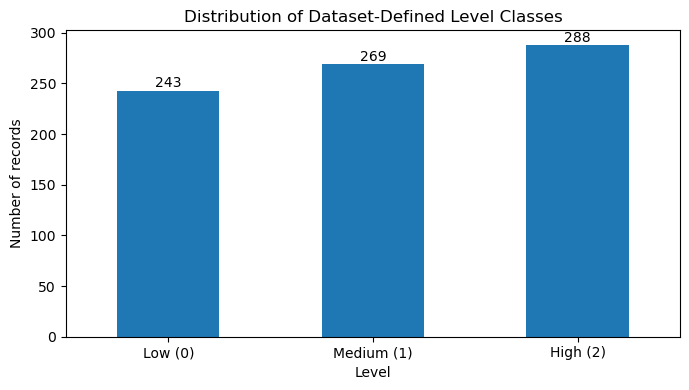

In [3]:
identifier_cols=['index','Patient Id']; target='Level'
X=raw.drop(columns=identifier_cols+[target]).copy()
# Fix only the obvious header spelling for display; values and row order never changed.
X=X.rename(columns={'Swal0ing Difficulty':'Swallowing Difficulty'})
y=raw[target].astype(int).copy()
assert X.shape==(800,23)
assert all(pd.api.types.is_numeric_dtype(X[c]) for c in X)
summary=pd.DataFrame({'Quantity':['Rows','Original columns','Predictor columns','Identifiers','Classes','Missing predictor cells','Missing target values','Exact full-row duplicates','Unique predictor profiles','Repeated predictor rows'],
'Value':[len(raw),raw.shape[1],X.shape[1],len(identifier_cols),len(CLASSES),int(X.isna().sum().sum()),int(y.isna().sum()),int(raw.duplicated().sum()),int(X.drop_duplicates().shape[0]),int(X.duplicated().sum())]})
display(summary)
summary.to_csv(OUT/'table_dataset_audit.csv',index=False)
class_counts=y.value_counts().reindex(CLASSES,fill_value=0)
class_table=pd.DataFrame({'Class':LABELS,'Count':class_counts.values,'Percent':(100*class_counts/len(y)).values})
display(class_table)
class_table.to_csv(OUT/'table_class_distribution.csv',index=False)
ax=class_counts.plot(kind='bar',title='Distribution of Dataset-Defined Level Classes',figsize=(7,4))
ax.set_xticklabels(LABELS,rotation=0);ax.set_ylabel('Number of records')
for i,v in enumerate(class_counts):ax.text(i,v+3,str(v),ha='center')
plt.tight_layout();plt.savefig(OUT/'fig_class_distribution.png',dpi=180);plt.show()


In [4]:
# A stable group identifier for identical *complete predictor profiles*.
profile_id=pd.util.hash_pandas_object(X,index=False).astype(str)
conflicts=(pd.DataFrame({'profile':profile_id,'level':y}).groupby('profile')['level'].nunique()>1).sum()
print('Distinct predictor profiles:',profile_id.nunique())
print('Profiles assigned contradictory class labels:',int(conflicts))
print('Repeated profiles:',int(X.duplicated().sum()))
# Patient Id uniqueness does not guarantee feature-profile independence.
print('Distinct Patient IDs:',raw['Patient Id'].nunique())


Distinct predictor profiles: 148
Profiles assigned contradictory class labels: 0
Repeated profiles: 652
Distinct Patient IDs: 800


In [5]:
X_train,X_test,y_train,y_test,group_train,group_test=train_test_split(X,y,profile_id,test_size=.2,random_state=SEED,stratify=y)
rf=RandomForestClassifier(n_estimators=100,random_state=SEED,n_jobs=-1)
rf.fit(X_train,y_train)
yp=rf.predict(X_test)
assert len(X_train)==640 and len(X_test)==160
seen_profiles=group_test.isin(set(group_train))
print('Training/test:',len(X_train),len(X_test),'test records whose profile also occurs in training:',int(seen_profiles.sum()))
print('Accuracy (not clinical validity):',accuracy_score(y_test,yp))


Training/test: 640 160 test records whose profile also occurs in training: 148
Accuracy (not clinical validity): 1.0


,Validation,Class,Support,Precision,Recall_sensitivity,Specificity_OVR,FNR_OVR,FPR_OVR,F1
0,Stratified random holdout,Low (0),48,1.0,1.0,1.0,0.0,0.0,1.0
1,Stratified random holdout,Medium (1),54,1.0,1.0,1.0,0.0,0.0,1.0
2,Stratified random holdout,High (2),58,1.0,1.0,1.0,0.0,0.0,1.0


,Validation,N,Accuracy,Error_rate_1_minus_accuracy,Balanced_accuracy,Macro_precision,Macro_recall,Macro_F1,Weighted_precision,Weighted_recall,Weighted_F1,Cohen_kappa
0,Stratified random holdout,160,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


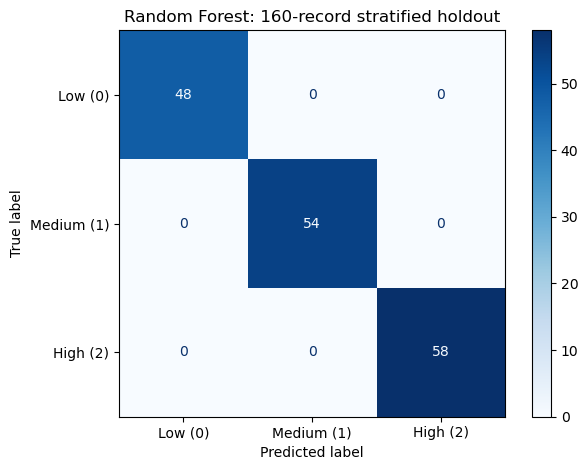

In [6]:
def metrics_table(y_true,y_pred,model_name):
    prec,rec,f1,sup=precision_recall_fscore_support(y_true,y_pred,labels=CLASSES,zero_division=0)
    mat=confusion_matrix(y_true,y_pred,labels=CLASSES)
    rows=[]
    for i,c in enumerate(CLASSES):
        tp=float(mat[i,i]);fn=float(mat[i,:].sum()-tp);fp=float(mat[:,i].sum()-tp);tn=float(mat.sum()-tp-fn-fp)
        rows.append({'Validation':model_name,'Class':LABELS[i],'Support':int(sup[i]),'Precision':prec[i],
                     'Recall_sensitivity':rec[i],'Specificity_OVR':tn/(tn+fp) if (tn+fp)>0 else np.nan,
                     'FNR_OVR':fn/(tp+fn) if tp+fn else np.nan,'FPR_OVR':fp/(tn+fp) if tn+fp else np.nan,'F1':f1[i]})
    out=pd.DataFrame(rows)
    macro=precision_recall_fscore_support(y_true,y_pred,labels=CLASSES,average='macro',zero_division=0)
    weighted=precision_recall_fscore_support(y_true,y_pred,labels=CLASSES,average='weighted',zero_division=0)
    overall={'Validation':model_name,'N':len(y_true),'Accuracy':accuracy_score(y_true,y_pred),
             'Error_rate_1_minus_accuracy':1-accuracy_score(y_true,y_pred),
             'Balanced_accuracy':balanced_accuracy_score(y_true,y_pred),'Macro_precision':macro[0],
             'Macro_recall':macro[1],'Macro_F1':macro[2], 'Weighted_precision':weighted[0],
             'Weighted_recall':weighted[1],'Weighted_F1':weighted[2], 'Cohen_kappa':cohen_kappa_score(y_true,y_pred)}
    return out,overall,mat
standard_classes,standard_summary,cm=metrics_table(y_test,yp,'Stratified random holdout')
display(standard_classes);display(pd.DataFrame([standard_summary]))
ConfusionMatrixDisplay(cm,display_labels=LABELS).plot(cmap='Blues',values_format='d')
plt.title('Random Forest: 160-record stratified holdout');plt.tight_layout()
plt.savefig(OUT/'fig_rf_stratified_confusion.png',dpi=180);plt.show()
standard_classes.to_csv(OUT/'table_rf_holdout_per_class.csv',index=False)


,Validation,Class,Support,Precision,Recall_sensitivity,Specificity_OVR,FNR_OVR,FPR_OVR,F1
0,Group-disjoint holdout,Low (0),57,1.0,1.0,1.0,0.0,0.0,1.0
1,Group-disjoint holdout,Medium (1),48,1.0,1.0,1.0,0.0,0.0,1.0
2,Group-disjoint holdout,High (2),53,1.0,1.0,1.0,0.0,0.0,1.0


,Validation,N,Accuracy,Error_rate_1_minus_accuracy,Balanced_accuracy,Macro_precision,Macro_recall,Macro_F1,Weighted_precision,Weighted_recall,Weighted_F1,Cohen_kappa
0,Group-disjoint holdout,158,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


Grouped test size: 158 unique test profiles: 30


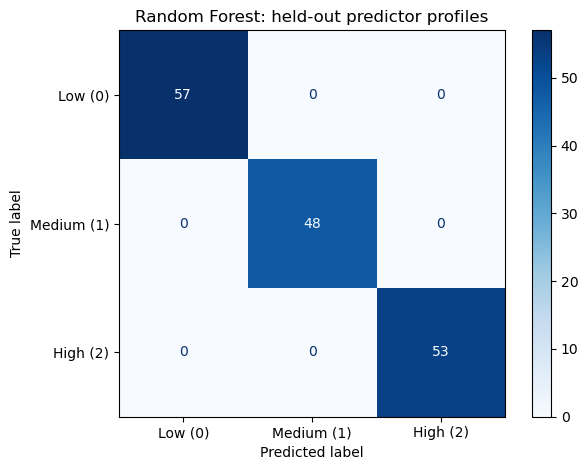

In [7]:
gss=GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED)
itr,ite=next(gss.split(X,y,groups=profile_id))
Xg_train,Xg_test=X.iloc[itr],X.iloc[ite]
yg_train,yg_test=y.iloc[itr],y.iloc[ite]
assert not set(profile_id.iloc[itr]).intersection(set(profile_id.iloc[ite]))
grf=RandomForestClassifier(n_estimators=100,random_state=SEED,n_jobs=-1).fit(Xg_train,yg_train)
gyp=grf.predict(Xg_test)
group_classes,group_summary,gcm=metrics_table(yg_test,gyp,'Group-disjoint holdout')
display(group_classes);display(pd.DataFrame([group_summary]))
print('Grouped test size:',len(ite),'unique test profiles:',profile_id.iloc[ite].nunique())
ConfusionMatrixDisplay(gcm,display_labels=LABELS).plot(cmap='Blues',values_format='d')
plt.title('Random Forest: held-out predictor profiles');plt.tight_layout()
plt.savefig(OUT/'fig_rf_grouped_confusion.png',dpi=180);plt.show()
group_classes.to_csv(OUT/'table_rf_grouped_per_class.csv',index=False)


,Validation,Class,Support,Precision,Recall_sensitivity,Specificity_OVR,FNR_OVR,FPR_OVR,F1
0,5-fold stratified group CV (pooled OOF),Low (0),243,1.00000,0.967078,1.000000,0.032922,0.000000,0.983264
1,5-fold stratified group CV (pooled OOF),Medium (1),269,0.94386,1.000000,0.969868,0.000000,0.030132,0.971119
2,5-fold stratified group CV (pooled OOF),High (2),288,1.00000,0.972222,1.000000,0.027778,0.000000,0.985915


,Validation,N,Accuracy,Error_rate_1_minus_accuracy,Balanced_accuracy,Macro_precision,Macro_recall,Macro_F1,Weighted_precision,Weighted_recall,Weighted_F1,Cohen_kappa
0,5-fold stratified group CV (pooled OOF),800,0.98,0.02,0.979767,0.981287,0.979767,0.980099,0.981123,0.98,0.980135,0.969924


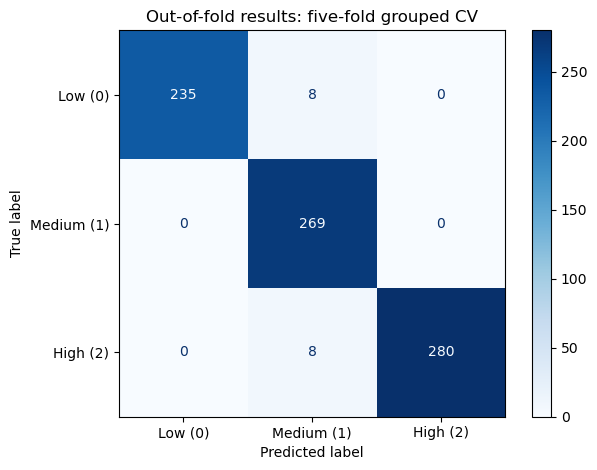

In [8]:
cv=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED)
cv_model=RandomForestClassifier(n_estimators=100,random_state=SEED,n_jobs=-1)
cv_pred=cross_val_predict(cv_model,X,y,cv=cv,groups=profile_id,n_jobs=1,method='predict')
cv_classes,cv_summary,cv_cm=metrics_table(y,cv_pred,'5-fold stratified group CV (pooled OOF)')
display(cv_classes);display(pd.DataFrame([cv_summary]))
ConfusionMatrixDisplay(cv_cm,display_labels=LABELS).plot(cmap='Blues',values_format='d')
plt.title('Out-of-fold results: five-fold grouped CV');plt.tight_layout()
plt.savefig(OUT/'fig_rf_grouped_cv_confusion.png',dpi=180);plt.show()
cv_classes.to_csv(OUT/'table_rf_grouped_cv_per_class.csv',index=False)
pd.DataFrame({'row_index':np.arange(len(y)),'observed_level':y,'grouped_cv_prediction':cv_pred}).to_csv(OUT/'grouped_cv_predictions.csv',index=False)


,Validation,N,Accuracy,Macro_precision,Macro_recall,Macro_F1
0,Random Forest,158,1.000000,1.000000,1.000000,1.00000
2,Extra Trees,158,1.000000,1.000000,1.000000,1.00000
3,Hist Gradient Boosting,158,1.000000,1.000000,1.000000,1.00000
4,Logistic Regression (scaled),158,1.000000,1.000000,1.000000,1.00000
1,Decision Tree,158,0.892405,0.919048,0.900585,0.89551


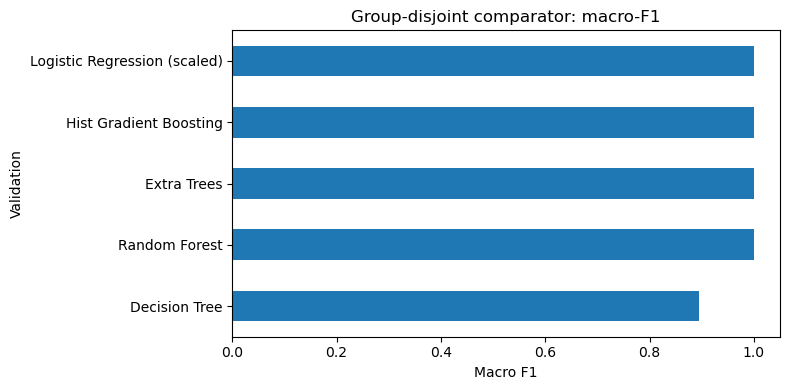

In [9]:
models={
 'Random Forest':RandomForestClassifier(n_estimators=100,random_state=SEED,n_jobs=-1),
 'Decision Tree':DecisionTreeClassifier(random_state=SEED),
 'Extra Trees':ExtraTreesClassifier(n_estimators=100,random_state=SEED,n_jobs=-1),
 'Hist Gradient Boosting':HistGradientBoostingClassifier(random_state=SEED),
 'Logistic Regression (scaled)':make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,random_state=SEED))}
comparison=[]
for name,est in models.items():
    est.fit(Xg_train,yg_train)
    pred=est.predict(Xg_test)
    _,row,_=metrics_table(yg_test,pred,name)
    comparison.append(row)
comparison=pd.DataFrame(comparison).sort_values('Macro_F1',ascending=False)
display(comparison[['Validation','N','Accuracy','Macro_precision','Macro_recall','Macro_F1']])
comparison.to_csv(OUT/'table_baseline_comparison.csv',index=False)
ax=comparison.sort_values('Macro_F1').plot.barh(x='Validation',y='Macro_F1',legend=False,figsize=(8,4),title='Group-disjoint comparator: macro-F1')
ax.set_xlabel('Macro F1');plt.tight_layout();plt.savefig(OUT/'fig_baseline_comparison.png',dpi=180);plt.show()


Group-holdout record-level bootstrap 95% percentile CI for accuracy: [1. 1.]
CAUTION: this bootstrap resamples records, not independent profiles; it is descriptive and may understate uncertainty.


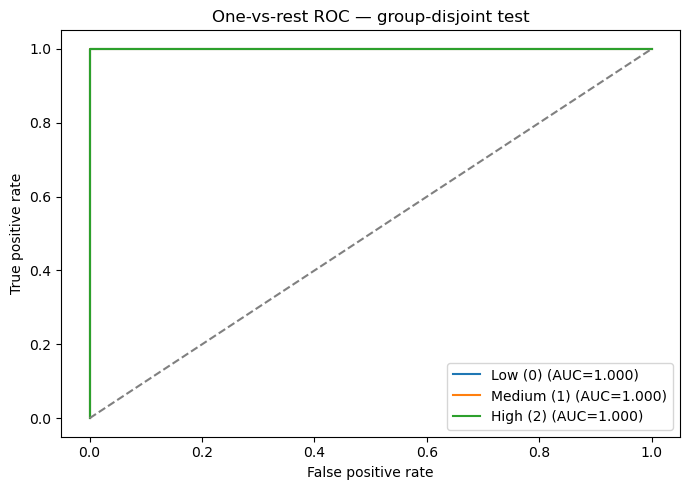

In [10]:
from sklearn.utils import resample
rng=np.random.default_rng(SEED)
boot=[]
yt=yg_test.to_numpy();pred=gyp
for j in range(2000):
    ids=rng.integers(0,len(yt),len(yt))
    boot.append(accuracy_score(yt[ids],pred[ids]))
print('Group-holdout record-level bootstrap 95% percentile CI for accuracy:',np.quantile(boot,[.025,.975]))
print('CAUTION: this bootstrap resamples records, not independent profiles; it is descriptive and may understate uncertainty.')
proba=grf.predict_proba(Xg_test)
fig,ax=plt.subplots(figsize=(7,5))
for j,c in enumerate(CLASSES):
    binary=(yg_test.to_numpy()==c).astype(int)
    fpr,tpr,_=roc_curve(binary,proba[:,j])
    ax.plot(fpr,tpr,label=f'{LABELS[j]} (AUC={auc(fpr,tpr):.3f})')
ax.plot([0,1],[0,1],'--',color='gray');ax.set(xlabel='False positive rate',ylabel='True positive rate',title='One-vs-rest ROC — group-disjoint test')
ax.legend();plt.tight_layout();plt.savefig(OUT/'fig_grouped_ovr_roc.png',dpi=180);plt.show()


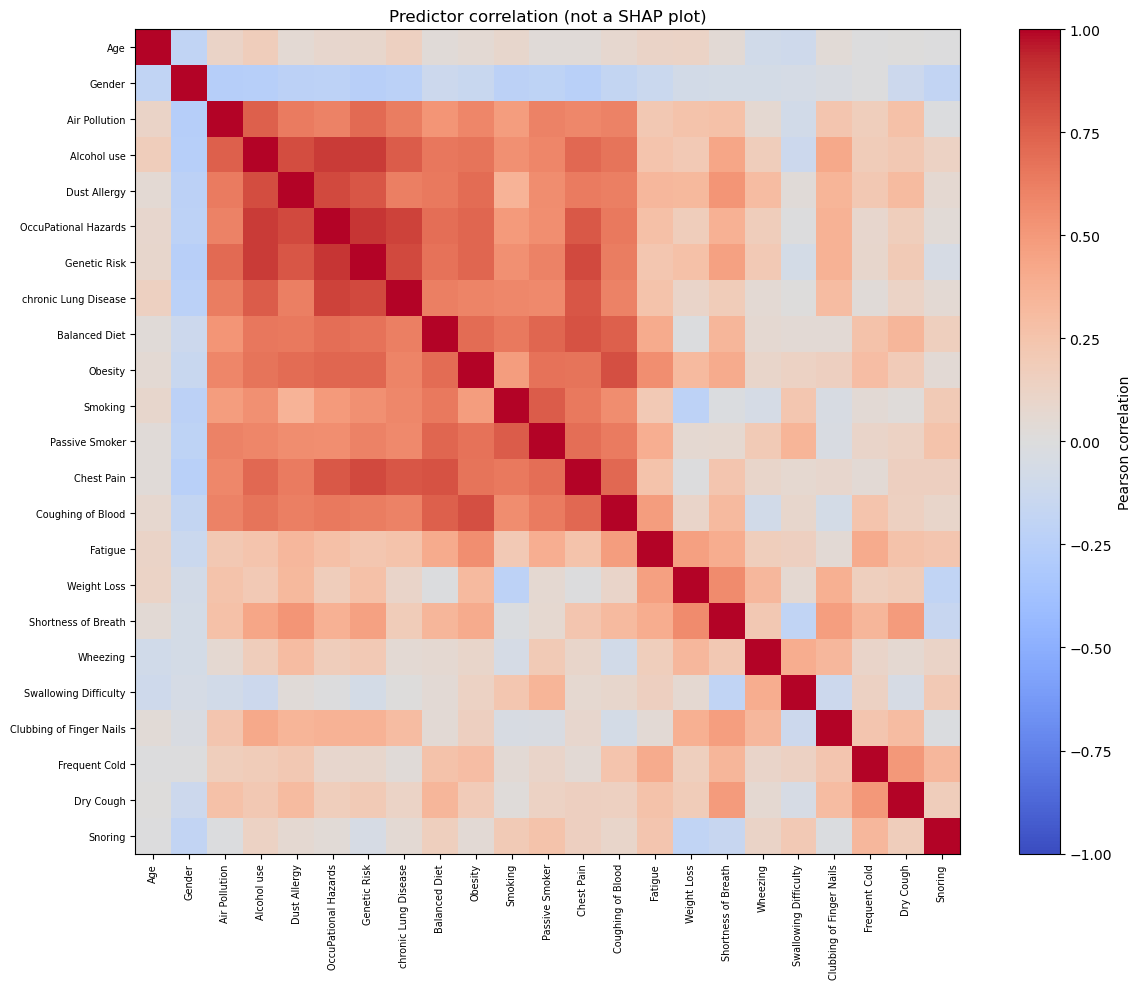

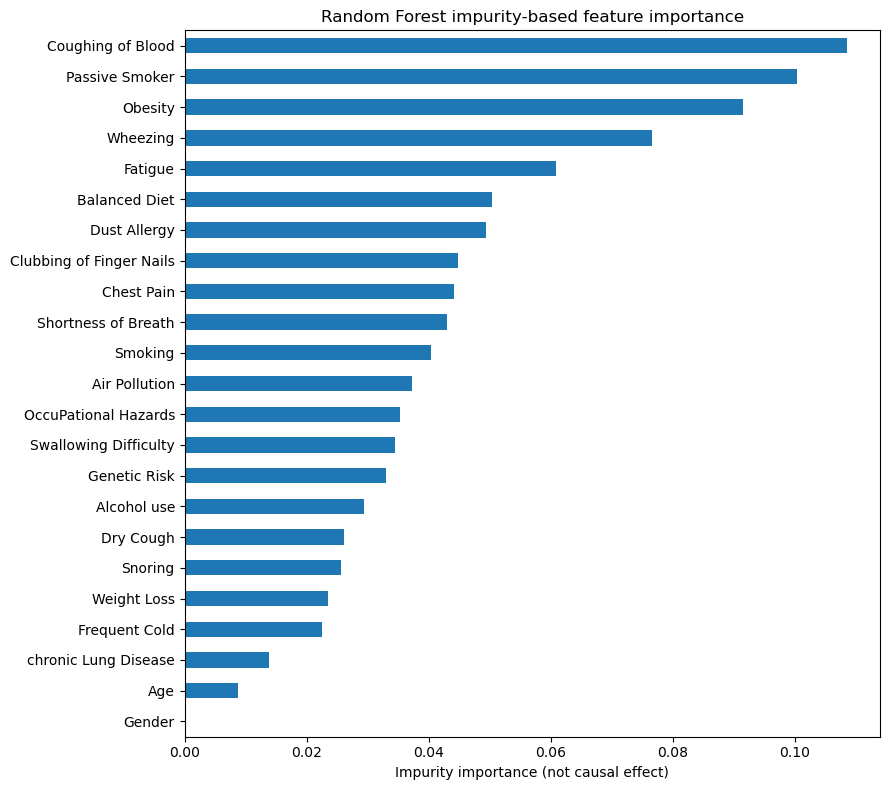

In [11]:
corr=X.corr(numeric_only=True)
fig,ax=plt.subplots(figsize=(13,10));im=ax.imshow(corr,cmap='coolwarm',vmin=-1,vmax=1)
ax.set_xticks(range(len(X.columns)),X.columns,rotation=90,fontsize=7)
ax.set_yticks(range(len(X.columns)),X.columns,fontsize=7);fig.colorbar(im,ax=ax,label='Pearson correlation')
ax.set_title('Predictor correlation (not a SHAP plot)');plt.tight_layout()
plt.savefig(OUT/'fig_predictor_correlation.png',dpi=180);plt.show()
importance=pd.Series(grf.feature_importances_,index=X.columns).sort_values()
ax=importance.plot.barh(figsize=(9,8),title='Random Forest impurity-based feature importance')
ax.set_xlabel('Impurity importance (not causal effect)');plt.tight_layout();plt.savefig(OUT/'fig_rf_importance.png',dpi=180);plt.show()
importance.sort_values(ascending=False).rename('importance').to_csv(OUT/'table_feature_importance.csv')


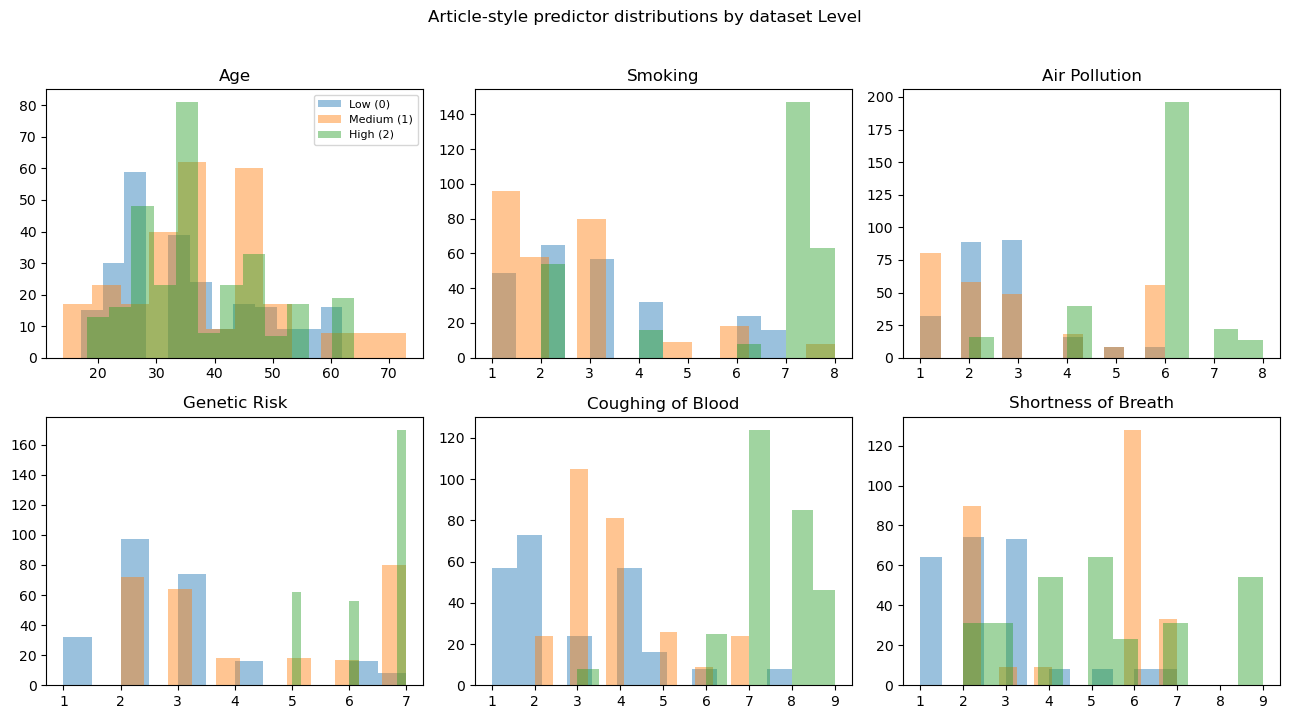

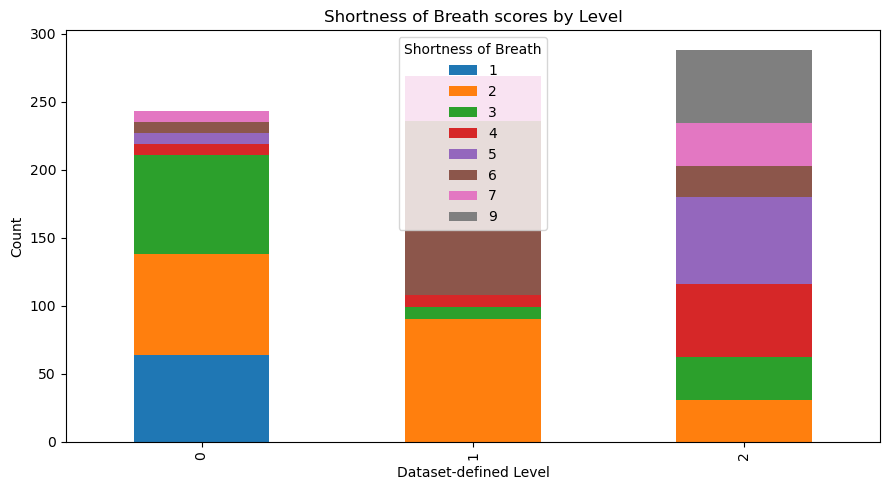

In [12]:
fig,axes=plt.subplots(2,3,figsize=(13,7))
features=['Age','Smoking','Air Pollution','Genetic Risk','Coughing of Blood','Shortness of Breath']
for ax,feat in zip(axes.flat,features):
    for cls in CLASSES:
        vals=X.loc[y==cls,feat]
        ax.hist(vals,bins=12,alpha=.45,label=LABELS[cls])
    ax.set_title(feat)
axes.flat[0].legend(fontsize=8)
fig.suptitle('Article-style predictor distributions by dataset Level',y=1.02)
plt.tight_layout();plt.savefig(OUT/'fig_feature_distributions.png',dpi=180);plt.show()
ct=pd.crosstab(y,X['Shortness of Breath'])
ax=ct.plot(kind='bar',stacked=True,figsize=(9,5),title='Shortness of Breath scores by Level')
ax.set_xlabel('Dataset-defined Level');ax.set_ylabel('Count');plt.tight_layout()
plt.savefig(OUT/'fig_symptom_stacked.png',dpi=180);plt.show()


SHAP version: 0.50.0


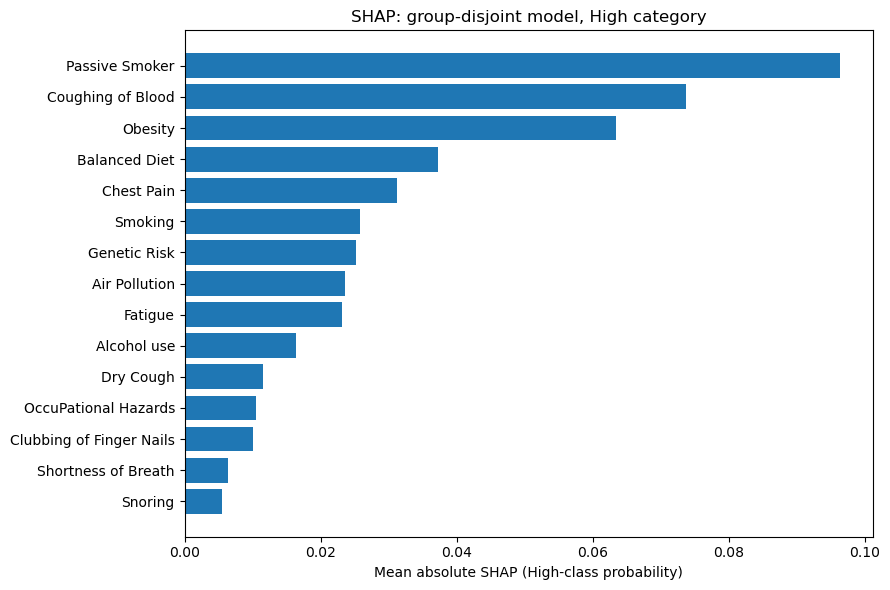

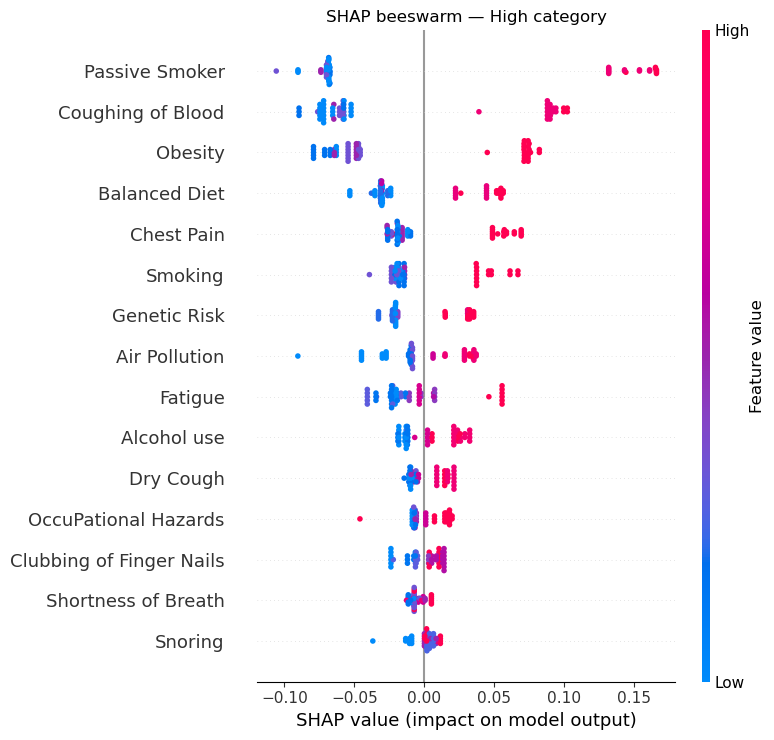

In [13]:
try:
 import shap
 from packaging.version import Version
 print('SHAP version:',shap.__version__)
 shap_explainer=shap.TreeExplainer(grf)
 # Only evaluate a modest subset for fast reproducible graph generation.
 explain_X=Xg_test.iloc[:min(60,len(Xg_test))].copy()
 raw_shap=shap_explainer.shap_values(explain_X)
 # Handle both legacy list(class arrays) and current (rows,features,classes) layouts.
 if isinstance(raw_shap,list):
     shap3=np.stack(raw_shap,axis=2)
 else:
     shap3=np.asarray(raw_shap)
 if shap3.ndim==2 and len(CLASSES)==2: shap3=np.stack([-shap3,shap3],axis=2)
 assert shap3.shape==(len(explain_X),X.shape[1],len(CLASSES)), f'Unexpected SHAP array shape {shap3.shape}'
 class_i=2 # High Level
 magnitudes=np.abs(shap3[:,:,class_i]).mean(axis=0)
 inds=np.argsort(magnitudes)[-15:]
 plt.figure(figsize=(9,6));plt.barh(X.columns[inds],magnitudes[inds]);plt.xlabel('Mean absolute SHAP (High-class probability)')
 plt.title('SHAP: group-disjoint model, High category');plt.tight_layout()
 plt.savefig(OUT/'fig_shap_high_global.png',dpi=180);plt.show()
 shap.summary_plot(shap3[:,:,class_i],explain_X,show=False,max_display=15)
 plt.title('SHAP beeswarm — High category');plt.tight_layout();plt.savefig(OUT/'fig_shap_high_beeswarm.png',dpi=180,bbox_inches='tight');plt.show()
 pd.DataFrame({'Feature':X.columns,'Mean_abs_SHAP_High':magnitudes}).sort_values('Mean_abs_SHAP_High',ascending=False).to_csv(OUT/'table_shap_high.csv',index=False)
except ImportError:
 print('SHAP not installed: install with pip install shap, then rerun this cell.')


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


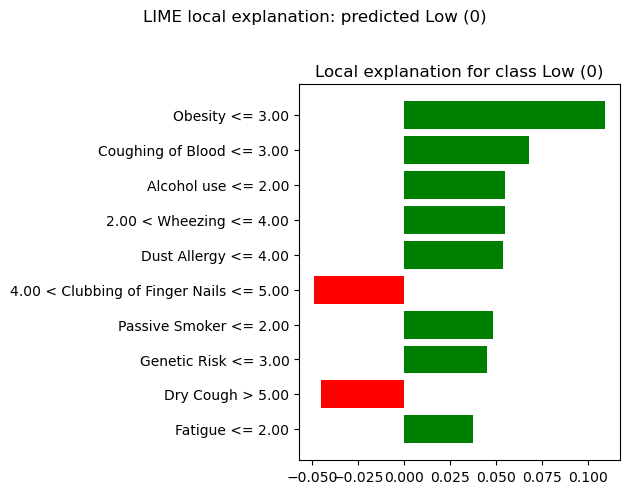

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


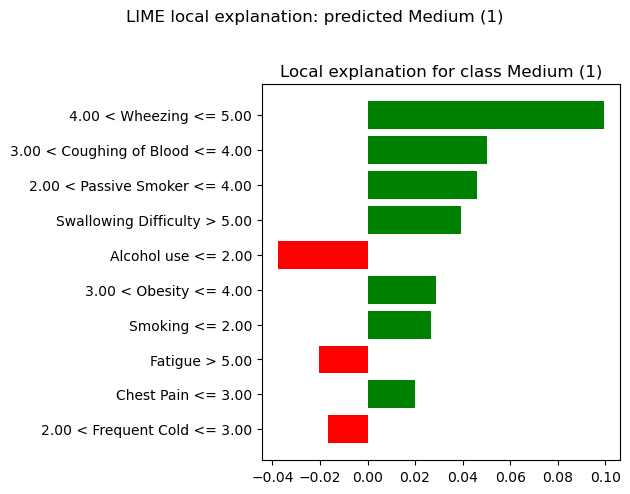

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


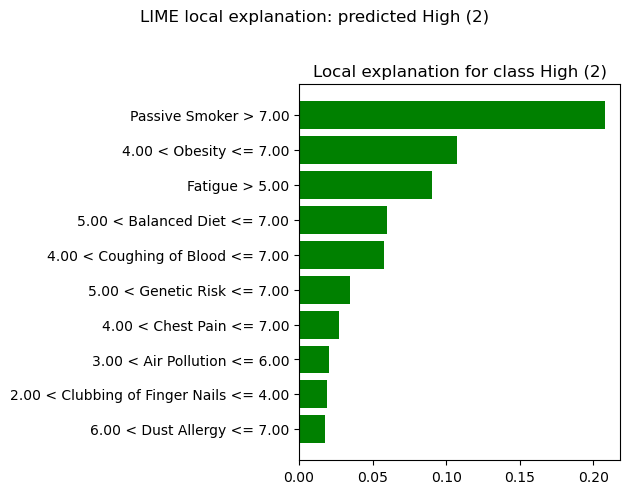

In [14]:
try:
 from lime.lime_tabular import LimeTabularExplainer
 lime_x=LimeTabularExplainer(training_data=Xg_train.to_numpy(),feature_names=list(X.columns),
   class_names=LABELS,mode='classification',discretize_continuous=True,random_state=SEED)
 for cl in CLASSES:
    matching=np.where(gyp==cl)[0]
    if len(matching)==0: continue
    pos=int(matching[0])
    exp=lime_x.explain_instance(Xg_test.iloc[pos].to_numpy(),grf.predict_proba,num_features=10,labels=[cl],num_samples=2000)
    fig=exp.as_pyplot_figure(label=cl)
    fig.suptitle(f'LIME local explanation: predicted {LABELS[cl]}',y=1.02)
    fig.tight_layout();fig.savefig(OUT/f'fig_lime_class_{cl}.png',dpi=180,bbox_inches='tight');plt.show()
    pd.DataFrame(exp.as_list(label=cl),columns=['LIME interval/feature','Local surrogate weight']).to_csv(OUT/f'table_lime_class_{cl}.csv',index=False)
except ImportError:
 print('LIME not installed in this environment. Install `lime` and rerun this cell; no substitute method is labelled LIME.')


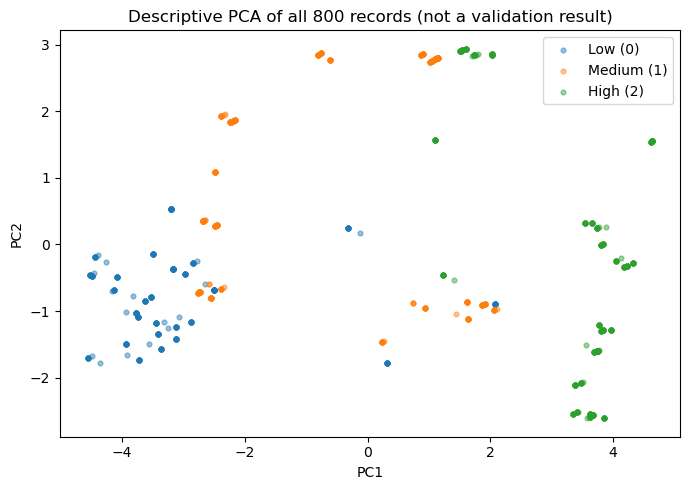

In [15]:
# Descriptive visualization, never fitted on the test set for predictive modeling.
Xp=StandardScaler().fit_transform(X)
z=PCA(n_components=2,random_state=SEED).fit_transform(Xp)
fig,ax=plt.subplots(figsize=(7,5))
for cl in CLASSES:
 a=z[y.to_numpy()==cl];ax.scatter(a[:,0],a[:,1],s=12,alpha=.45,label=LABELS[cl])
ax.legend();ax.set(xlabel='PC1',ylabel='PC2',title='Descriptive PCA of all 800 records (not a validation result)')
plt.tight_layout();plt.savefig(OUT/'fig_pca_descriptive.png',dpi=180);plt.show()


In [16]:
reported={'Accuracy':.9714,'Sensitivity':.9774,'Precision':.9923,'F1':.9990,'Miss rate':.0286}
reconciliation=pd.DataFrame([
 {'Statistic':'Accuracy','Originally reported':reported['Accuracy'],'Recomputed stratified holdout':standard_summary['Accuracy'],'Recomputed group-disjoint holdout':group_summary['Accuracy'],'Grouped CV pooled OOF':cv_summary['Accuracy']},
 {'Statistic':'Macro recall / sensitivity','Originally reported':reported['Sensitivity'],'Recomputed stratified holdout':standard_summary['Macro_recall'],'Recomputed group-disjoint holdout':group_summary['Macro_recall'],'Grouped CV pooled OOF':cv_summary['Macro_recall']},
 {'Statistic':'Macro precision','Originally reported':reported['Precision'],'Recomputed stratified holdout':standard_summary['Macro_precision'],'Recomputed group-disjoint holdout':group_summary['Macro_precision'],'Grouped CV pooled OOF':cv_summary['Macro_precision']},
 {'Statistic':'Macro F1','Originally reported':reported['F1'],'Recomputed stratified holdout':standard_summary['Macro_F1'],'Recomputed group-disjoint holdout':group_summary['Macro_F1'],'Grouped CV pooled OOF':cv_summary['Macro_F1']},
 {'Statistic':'Overall error rate (NOT FNR)','Originally reported':reported['Miss rate'],'Recomputed stratified holdout':standard_summary['Error_rate_1_minus_accuracy'],'Recomputed group-disjoint holdout':group_summary['Error_rate_1_minus_accuracy'],'Grouped CV pooled OOF':cv_summary['Error_rate_1_minus_accuracy']}
])
display(reconciliation)
reconciliation.to_csv(OUT/'table_manuscript_vs_recomputed.csv',index=False)
pd.DataFrame([standard_summary,group_summary,cv_summary]).to_csv(OUT/'table_all_validation_summary.csv',index=False)
print('Output files:',len(list(OUT.iterdir())),'in',OUT.resolve())


,Statistic,Originally reported,Recomputed stratified holdout,Recomputed group-disjoint holdout,Grouped CV pooled OOF
0,Accuracy,0.9714,1.0,1.0,0.980000
1,Macro recall / sensitivity,0.9774,1.0,1.0,0.979767
2,Macro precision,0.9923,1.0,1.0,0.981287
3,Macro F1,0.9990,1.0,1.0,0.980099
4,Overall error rate (NOT FNR),0.0286,0.0,0.0,0.020000


Output files: 30 in C:\Users\salman.muneer.PG\lung_outputs
